# PDAS Warm-Start Audit

**Numerical Practicum — University of Zurich**

This notebook investigates why two initialization strategies produce substantially different PDAS iteration counts for the one-dimensional Dirac obstacle problem.

Both methods begin with the same interpolated coarse solution:

$$
U_h^0=PU_H,
$$

where $P$ denotes the finite-element prolongation matrix.

**Method A — Primal warm start (fine-residual initialization)**

$$
\Lambda_h^{0,A}=A_hPU_H-F_h.
$$

The coarse solution is interpolated, and its residual is recomputed using the fine-grid stiffness matrix and load vector.

**Method B — Primal–dual warm start ($L^2$-Riesz transfer)**

$$
\Lambda_h^{0,B}=M_hPM_H^{-1}\Lambda_H.
$$

The coarse multiplier is reconstructed as a finite-element function, interpolated, and represented as a fine-grid dual vector. The inverse notation means solving a mass-matrix system.

**Both methods use exactly the same PDAS solver after initialization.** Only the initial dual vector differs.

## 1. Source code and reproducibility

The experiment imports the existing repository implementations. We record the Git commit, source-file checksums and execution timestamp.

The relevant algorithms are shown below in expandable source-code blocks.

In [1]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import hashlib
import html
import inspect
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, HTML


# --------------------------------------------------
# Locate repository
# --------------------------------------------------

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

assert (ROOT / "src/p1_nested_large.py").is_file(), (
    f"Cannot locate repository: {ROOT}"
)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


def timestamp():
    return datetime.now(
        ZoneInfo("Europe/Zurich")
    ).isoformat(timespec="seconds")


def git(*args):
    result = subprocess.run(
        ["git", *args],
        cwd=ROOT,
        capture_output=True,
        text=True,
        check=True,
    )
    return result.stdout.strip()


def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


# --------------------------------------------------
# Record exact source versions
# --------------------------------------------------

SOURCE_FILES = [
    "src/p1_nested_large.py",
    "src/p2_nested_large.py",
    "src/multiplier_l2_transfer.py",
    "experiments/compare_l2_multiplier_transfer.py",
]

SOURCE_HASHES = {
    name: sha256(ROOT / name)
    for name in SOURCE_FILES
}


def check_sources():
    for name, expected in SOURCE_HASHES.items():
        actual = sha256(ROOT / name)

        assert actual == expected, (
            f"Source changed since audit began: {name}"
        )


print("PDAS WARM-START AUDIT")
print("=" * 65)
print("Executed:", timestamp())
print("Git commit:", git("rev-parse", "HEAD"))
print("Working tree:", git("status", "--short") or "clean")
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Repository:", ROOT)

print("\nSource checksums:")

for name, digest in SOURCE_HASHES.items():
    print(f"{name}: {digest}")


# --------------------------------------------------
# Import unchanged repository algorithms
# --------------------------------------------------

from experiments.compare_l2_multiplier_transfer import (
    prepare_problem,
)

from src.p1_nested_large import (
    solve_pdas_p1,
    prolongate_p1,
)

from src.p2_nested_large import (
    solve_pdas_p2,
    prolongate_p2,
)

from src.multiplier_l2_transfer import (
    p1_riesz_coefficients,
    p2_riesz_coefficients,
    transfer_l2_multiplier_p1,
    transfer_l2_multiplier_p2,
)


SOURCE_FUNCTIONS = [
    prepare_problem,
    solve_pdas_p1,
    solve_pdas_p2,
    prolongate_p1,
    prolongate_p2,
    p1_riesz_coefficients,
    p2_riesz_coefficients,
    transfer_l2_multiplier_p1,
    transfer_l2_multiplier_p2,
]


# --------------------------------------------------
# Show exact imported functions
# --------------------------------------------------

def show_source(function):
    path = Path(inspect.getfile(function)).resolve()
    relative = str(path.relative_to(ROOT))

    assert relative in SOURCE_HASHES, (
        f"Unexpected imported source: {relative}"
    )

    check_sources()

    code = inspect.getsource(function)

    display(HTML(
        "<details>"
        f"<summary><strong>{html.escape(function.__name__)}</strong>"
        f" — {html.escape(relative)}</summary>"
        f"<pre>Inspected: {timestamp()}\n"
        f"SHA256: {SOURCE_HASHES[relative]}</pre>"
        f"<pre><code>{html.escape(code)}</code></pre>"
        "</details>"
    ))


for function in SOURCE_FUNCTIONS:
    show_source(function)

print("\nSource verification completed.")

PDAS WARM-START AUDIT
Executed: 2026-11-09T17:36:45+01:00
Git commit: d2b582938d4ec2c6eed0a3f13d6e6752c2565191
Working tree: ?? notebooks/
Python: 3.12.4
NumPy: 1.26.4
Repository: /Users/victorsieber/Desktop/UZH/Numerisches Praktikum/obstacle-problem-fem

Source checksums:
src/p1_nested_large.py: 2ce14b0b9a5aa61162296fd9b603ed07e0ead209846826de0458e04d634ec6d5
src/p2_nested_large.py: af49b6f8dd2abfa832c37deca5eae8d2423f078571f7439c9958220c8effdb35
src/multiplier_l2_transfer.py: dd3888bd3e4631718462831acb6b1af86243cf842434d7fc41a54b6e83084322
experiments/compare_l2_multiplier_transfer.py: 1c070a9895413bbb4787111ddf14481beb6ea8590e430843e05cd4131f4d4310



Source verification completed.


## 2. Mathematical consistency of both initializations

Let $V_H\subset V_h$ denote nested conforming finite-element spaces, and let $P$ be the corresponding prolongation matrix.

For consistently assembled FEM matrices, we have the Galerkin identities

$$
A_H=P^\top A_hP,
\qquad
F_H=P^\top F_h,
\qquad
M_H=P^\top M_hP.
$$

We show that both initialization strategies preserve the same coarse-grid dual functional.

### Method A: Fine-residual initialization

Recall that $\Lambda_H=A_HU_H-F_H$. Hence,

$$
\begin{aligned}
P^\top\Lambda_h^{0,A}
&=P^\top(A_hPU_H-F_h)\\
&=A_HU_H-F_H\\
&=\Lambda_H.
\end{aligned}
$$

### Method B: $L^2$-Riesz transfer

Similarly,

$$
\begin{aligned}
P^\top\Lambda_h^{0,B}
&=P^\top M_hPM_H^{-1}\Lambda_H\\
&=M_HM_H^{-1}\Lambda_H\\
&=\Lambda_H.
\end{aligned}
$$

Therefore,

$$
\boxed{
P^\top\Lambda_h^{0,A}
=
P^\top\Lambda_h^{0,B}
=
\Lambda_H.
}
$$

Equivalently,

$$
\boxed{
P^\top(\Lambda_h^{0,A}-\Lambda_h^{0,B})=0.
}
$$

**Interpretation:** Both fine-grid dual vectors agree on the coarse finite-element test space. Nevertheless, their individual fine-grid coefficients can differ substantially.

This matters because PDAS determines the initial active set componentwise:

$$
\mathcal C^0=
\left\{
i:\Lambda_{h,i}^0-c(U_{h,i}^0-\psi_i)>0
\right\}.
$$

Since the fine mesh has more degrees of freedom than the coarse mesh, $N_h>N_H$, the prolongation matrix satisfies

$$
P^\top\in\mathbb R^{N_H\times N_h}.
$$

By the rank–nullity theorem,

$$
\dim\ker(P^\top)
=N_h-\operatorname{rank}(P^\top)
\geq N_h-N_H>0.
$$

Thus, $\ker(P^\top)\neq\{0\}$.

We conclude, different fine-grid dual coefficients can therefore produce different initial active sets, despite preserving the same coarse-grid dual functional.

## 3. Numerical comparison: P1 and P2

We consider the one-dimensional Dirac obstacle problem

$$
f=-6-2\delta_{1/3}-\delta_{2/3},
\qquad \psi=-1,
$$

with homogeneous Dirichlet boundary conditions.

The coarse mesh contains 100 uniform elements and the fine mesh contains 1,000 uniform elements.

Both methods use the same:

- Coarse solution $U_H$ and multiplier $\Lambda_H$.
- Primal interpolation $U_h^0=PU_H$.
- Fine-grid stiffness matrix and load vector.
- PDAS solver, with $c=1$ and active-set stabilization as its stopping criterion.

Only the initial dual vector differs.

We compare iteration counts, verify equality of the final discrete solutions, and check the KKT residuals.

In [2]:
check_sources()

print("Numerical experiment:", timestamp())

M_COARSE = 100
M_FINE = 1000
MAXITER = 6000


def run_comparison():
    audit_cases = {}
    rows = []

    for degree in (1, 2):

        # ------------------------------------------
        # 1. Coarse problem
        # ------------------------------------------

        coarse_nodes = np.linspace(
            0.0, 1.0, M_COARSE + 1
        )

        solve_H, multiplier_H, _, _ = (
            prepare_problem(
                degree,
                coarse_nodes,
                MAXITER,
            )
        )

        U_H, info_H = solve_H(None, None)

        Lambda_H = multiplier_H(U_H)

        # ------------------------------------------
        # 2. Fine problem
        # ------------------------------------------

        fine_nodes = np.linspace(
            0.0, 1.0, M_FINE + 1
        )

        solve_h, multiplier_h, prolongate, transfer = (
            prepare_problem(
                degree,
                fine_nodes,
                MAXITER,
            )
        )

        # Identical primal initialization.
        U0 = prolongate(
            coarse_nodes,
            U_H,
            fine_nodes,
        )

        # ------------------------------------------
        # 3. Initial dual vectors
        # ------------------------------------------

        # Method A: fine-grid residual.
        Lambda_A = multiplier_h(U0)

        # Method B: L2-Riesz transfer.
        Lambda_B = transfer(
            coarse_nodes,
            Lambda_H,
            fine_nodes,
        )

        # ------------------------------------------
        # 4. Same PDAS solver
        # ------------------------------------------

        # None instructs the unchanged solver to
        # calculate A_h U0 - F_h internally.
        U_A, info_A = solve_h(U0, None)

        # Supply the Riesz-transferred dual vector.
        U_B, info_B = solve_h(U0, Lambda_B)

        # ------------------------------------------
        # 5. Correctness checks
        # ------------------------------------------

        difference = float(
            np.max(np.abs(U_A - U_B))
        )

        assert difference < 1e-8, (
            f"P{degree}: solutions differ."
        )

        for info in (info_A, info_B):
            assert info["min_gap"] >= -1e-8
            assert info["min_multiplier"] >= -1e-8
            assert info["max_complementarity"] < 1e-8

        # Save data for the next sections.
        audit_cases[degree] = {
            "coarse_nodes": coarse_nodes,
            "fine_nodes": fine_nodes,
            "U_H": U_H,
            "Lambda_H": Lambda_H,
            "U0": U0,
            "Lambda_A": Lambda_A,
            "Lambda_B": Lambda_B,
            "U_final": U_A,
            "multiplier_h": multiplier_h,
            "prolongate": prolongate,
            "info_A": info_A,
            "info_B": info_B,
            "solve_h": solve_h,
        }

        for name, info in [
            ("A: Fine residual", info_A),
            ("B: L2-Riesz", info_B),
        ]:

            rows.append({
                "FEM": f"P{degree}",
                "Method": name,
                "PDAS iterations": info["iterations"],
                "Min gap": info["min_gap"],
                "Min dual": info["min_multiplier"],
                "Max complementarity": (
                    info["max_complementarity"]
                ),
                "Solution difference": difference,
            })

    return audit_cases, pd.DataFrame(rows)


AUDIT_CASES, COMPARISON = run_comparison()

assert set(AUDIT_CASES) == {1, 2}

display(COMPARISON)

print("Stored FEM cases:", list(AUDIT_CASES.keys()))

Numerical experiment: 2026-11-09T17:36:51+01:00


,FEM,Method,PDAS iterations,Min gap,Min dual,Max complementarity,Solution difference
0,P1,A: Fine residual,139,0.0,-3.128608e-13,1.281736e-13,0.0
1,P1,B: L2-Riesz,8,0.0,-3.128608e-13,1.281736e-13,0.0
2,P2,A: Fine residual,278,0.0,-1.389777e-12,4.229390e-13,0.0
3,P2,B: L2-Riesz,3,0.0,-1.389777e-12,4.229390e-13,0.0


Stored FEM cases: [1, 2]


## 4. Numerical verification of coarse consistency

We now verify the theoretical identity

$$
P^\top\Lambda_h^{0,A}
=
P^\top\Lambda_h^{0,B}
=
\Lambda_H.
$$

For this diagnostic, the prolongation matrix $P$ is constructed by applying the repository's original interpolation function to every coarse basis vector.

We also compare the predicted initial active sets against the converged discrete active set.

The explicit prolongation matrix is used only for verification, not in the production solver.

In [3]:
check_sources()

print("Consistency verification:", timestamp())

assert set(AUDIT_CASES) == {1, 2}, (
    "Run Section 3 before Section 4."
)


def verify_consistency(audit_cases):
    rows = []

    for degree in (1, 2):

        case = audit_cases[degree]

        coarse_nodes = case["coarse_nodes"]
        fine_nodes = case["fine_nodes"]

        U_H = case["U_H"]
        Lambda_H = case["Lambda_H"]

        U0 = case["U0"]
        Lambda_A = case["Lambda_A"]
        Lambda_B = case["Lambda_B"]

        prolongate = case["prolongate"]

        # ------------------------------------------
        # 1. Construct prolongation matrix P
        # ------------------------------------------

        n_H = len(U_H)
        basis = np.eye(n_H)

        P = np.column_stack([
            prolongate(
                coarse_nodes,
                basis[:, j],
                fine_nodes,
            )
            for j in range(n_H)
        ])

        # Verify primal interpolation.
        assert np.allclose(
            P @ U_H,
            U0,
            atol=1e-12,
        )

        # ------------------------------------------
        # 2. Verify the dual identities
        # ------------------------------------------

        error_A = float(
            np.max(
                np.abs(P.T @ Lambda_A - Lambda_H)
            )
        )

        error_B = float(
            np.max(
                np.abs(P.T @ Lambda_B - Lambda_H)
            )
        )

        assert error_A < 1e-9
        assert error_B < 1e-9

        # ------------------------------------------
        # 3. Compare initial contact sets
        # ------------------------------------------

        U_final = case["U_final"]

        Lambda_final = case["multiplier_h"](
            U_final
        )

        # Obstacle psi = -1 and c = 1.
        active_final = (
            Lambda_final - (U_final + 1.0) > 0.0
        )

        for name, Lambda, error, info in [
            (
                "A: Fine residual",
                Lambda_A,
                error_A,
                case["info_A"],
            ),
            (
                "B: L2-Riesz",
                Lambda_B,
                error_B,
                case["info_B"],
            ),
        ]:

            active_initial = (
                Lambda - (U0 + 1.0) > 0.0
            )

            incorrect = int(
                np.count_nonzero(
                    active_initial != active_final
                )
            )

            rows.append({
                "FEM": f"P{degree}",
                "Method": name,
                "Coarse consistency error": error,
                "Incorrect initial active nodes": incorrect,
                "Max |initial dual|": float(
                    np.max(np.abs(Lambda))
                ),
                "PDAS iterations": info["iterations"],
            })

    return pd.DataFrame(rows)

CONSISTENCY = verify_consistency(AUDIT_CASES)

display(CONSISTENCY)

# --------------------------------------------------
# First PDAS update: compare C0, C1 against C*
# --------------------------------------------------

def first_pdas_update(degree, solve_h, U0, initial_multiplier):
    """Observe the first update in the unchanged PDAS solver."""

    target = solve_pdas_p1 if degree == 1 else solve_pdas_p2

    source, first_line = inspect.getsourcelines(target)
    watch = [
        first_line + k
        for k, line in enumerate(source)
        if line.strip() == "if verbose:"
    ]
    assert len(watch) == 1, "PDAS source layout changed."

    captured = []

    def tracer(frame, event, arg):
        if event == "call":
            return tracer if frame.f_code is target.__code__ else None

        if event == "line" and frame.f_lineno == watch[0] and not captured:
            assert frame.f_locals["iteration"] == 1

            captured.append((
                frame.f_locals["active"].copy(),
                frame.f_locals["new_active"].copy(),
            ))
            return None

        return tracer

    previous_trace = sys.gettrace()

    try:
        sys.settrace(tracer)
        U, info = solve_h(U0, initial_multiplier)
    finally:
        sys.settrace(previous_trace)

    assert len(captured) == 1
    return captured[0], U, info


rows = []

for degree in (1, 2):
    case = AUDIT_CASES[degree]

    U_final = case["U_final"]
    Lambda_final = case["multiplier_h"](U_final)

    # Converged active set, psi = -1 and c = 1
    C_final = Lambda_final - (U_final + 1.0) > 0.0

    methods = [
        ("A: Fine residual", case["Lambda_A"], None, case["info_A"]),
        ("B: L2-Riesz", case["Lambda_B"], case["Lambda_B"], case["info_B"]),
    ]

    for name, Lambda0, initial_multiplier, original_info in methods:

        (C0, C1), U_replay, info = first_pdas_update(
            degree,
            case["solve_h"],
            case["U0"],
            initial_multiplier,
        )

        # Check that we observed the original algorithm.
        assert np.array_equal(
            C0, Lambda0 - (case["U0"] + 1.0) > 0.0
        )
        assert np.allclose(U_replay, U_final, atol=1e-10, rtol=0)
        assert info["iterations"] == original_info["iterations"]

        rows.append({
            "FEM": f"P{degree}",
            "Method": name,
            "Incorrect C0": np.count_nonzero(C0 != C_final),
            "Incorrect C1": np.count_nonzero(C1 != C_final),
            "PDAS iterations": info["iterations"],
        })

FIRST_UPDATE = pd.DataFrame(rows)
display(FIRST_UPDATE)

Consistency verification: 2026-11-09T17:36:52+01:00


,FEM,Method,Coarse consistency error,Incorrect initial active nodes,Max |initial dual|,PDAS iterations
0,P1,A: Fine residual,2.700052e-13,45,1.387333,139
1,P1,B: L2-Riesz,1.387779e-17,8,0.009570,8
2,P2,A: Fine residual,9.057242e-13,18,1.602860,278
3,P2,B: L2-Riesz,9.020562e-17,2,0.004892,3


,FEM,Method,Incorrect C0,Incorrect C1,PDAS iterations
0,P1,A: Fine residual,45,139,139
1,P1,B: L2-Riesz,8,6,8
2,P2,A: Fine residual,18,280,278
3,P2,B: L2-Riesz,2,1,3


## 5. Fine-grid dual coefficients and active-set decisions

Although both initializations preserve the coarse-grid dual functional, their fine-grid coefficients differ.

Method A evaluates the fine-grid residual of the interpolated solution. Method B transfers a reconstructed multiplier function through the mass matrices.

We compare both dual vectors near the singular point $x=1/3$.

We also visualize the PDAS classification score

$$
s_i=\Lambda_{h,i}^0-(U_{h,i}^0-\psi_i),
$$

where $c=1$.

A node is initially classified as active precisely when

$$
s_i>0.
$$

The plots show how different fine-grid dual coefficients produce different initial contact-set predictions.

Visualization: 2026-11-09T17:36:52+01:00


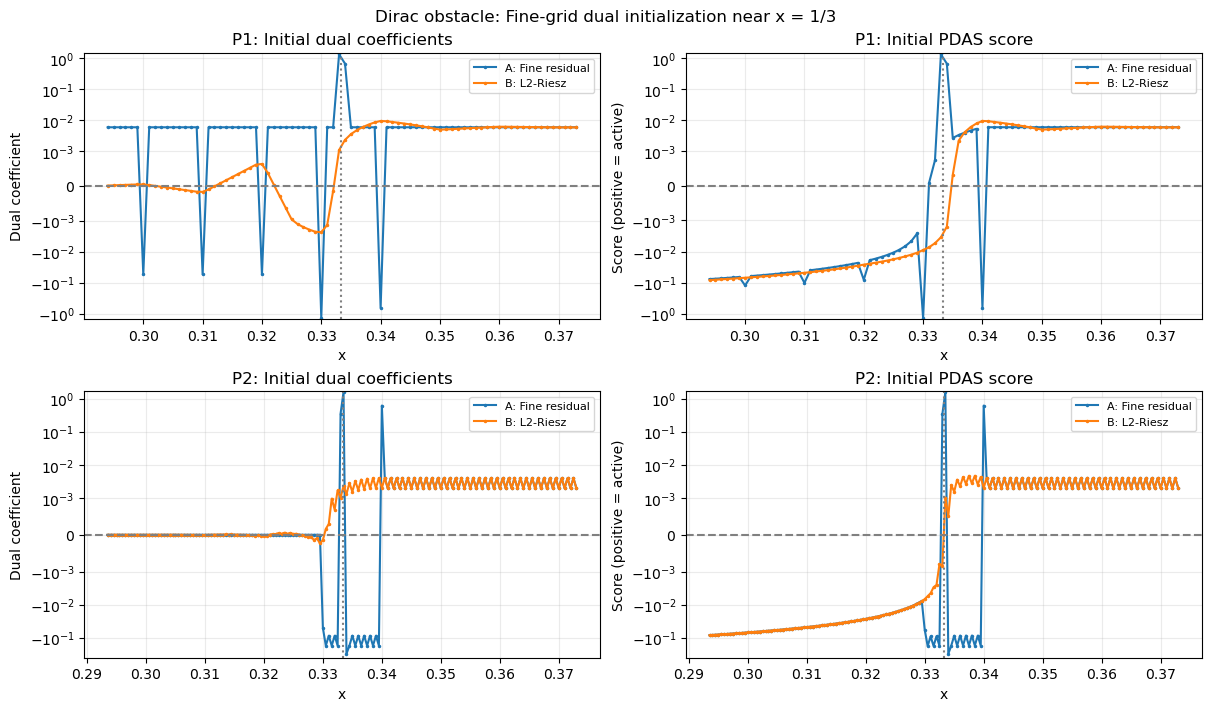

In [4]:
check_sources()

print("Visualization:", timestamp())

assert set(AUDIT_CASES) == {1, 2}


def dof_positions(degree, nodes):

    if degree == 1:
        return nodes[1:-1]

    M = len(nodes) - 1

    positions = np.empty(2 * M - 1)

    # P2 midpoint DOFs.
    positions[0::2] = (
        nodes[:-1] + nodes[1:]
    ) / 2

    # P2 interior vertex DOFs.
    positions[1::2] = nodes[1:-1]

    return positions


alpha = 1.0 / 3.0
window = 0.04

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 7),
    constrained_layout=True,
)

for row, degree in enumerate((1, 2)):

    case = AUDIT_CASES[degree]

    x = dof_positions(
        degree,
        case["fine_nodes"],
    )

    U0 = case["U0"]

    Lambda_A = case["Lambda_A"]
    Lambda_B = case["Lambda_B"]

    # PDAS classification scores.
    score_A = Lambda_A - (U0 + 1.0)
    score_B = Lambda_B - (U0 + 1.0)

    mask = np.abs(x - alpha) <= window

    # ------------------------------------------
    # Left: initial dual coefficients
    # ------------------------------------------

    ax = axes[row, 0]

    ax.plot(
        x[mask],
        Lambda_A[mask],
        ".-",
        markersize=3,
        label="A: Fine residual",
    )

    ax.plot(
        x[mask],
        Lambda_B[mask],
        ".-",
        markersize=3,
        label="B: L2-Riesz",
    )

    ax.set_title(
        f"P{degree}: Initial dual coefficients"
    )

    ax.set_ylabel("Dual coefficient")

    # ------------------------------------------
    # Right: active-set classification score
    # ------------------------------------------

    ax = axes[row, 1]

    ax.plot(
        x[mask],
        score_A[mask],
        ".-",
        markersize=3,
        label="A: Fine residual",
    )

    ax.plot(
        x[mask],
        score_B[mask],
        ".-",
        markersize=3,
        label="B: L2-Riesz",
    )

    ax.set_title(
        f"P{degree}: Initial PDAS score"
    )

    ax.set_ylabel("Score (positive = active)")

    for ax in axes[row]:

        ax.axhline(
            0.0,
            color="gray",
            linestyle="--",
        )

        ax.axvline(
            alpha,
            color="gray",
            linestyle=":",
        )

        ax.set_yscale(
            "symlog",
            linthresh=1e-3,
        )

        ax.set_xlabel("x")
        ax.grid(True, alpha=0.25)
        ax.legend(fontsize=8)

fig.suptitle(
    "Dirac obstacle: Fine-grid dual initialization near x = 1/3"
)

plt.show()

## 6. Conclusion

This investigation compares two warm-start strategies for the same P1/P2 PDAS obstacle solver.

### Mathematical result

Both methods use identical primal interpolation and preserve the same coarse-grid dual functional:

$$
P^\top\Lambda_h^{0,A}
=
P^\top\Lambda_h^{0,B}
=
\Lambda_H.
$$

The identity was verified numerically for both P1 and P2.

However, the fine-grid dual coefficients differ because the methods construct them differently.

### Numerical result

For the Dirac benchmark with 1,000 uniform elements:

| Initialization | P1 iterations | P2 iterations |
|---|---:|---:|
| A: Fine-residual warm start | 139 | 278 |
| B: $L^2$-Riesz warm start | 8 | 3 |

Both methods converge to the same discrete solution and satisfy the KKT conditions to numerical precision.

The Riesz initialization also produces fewer incorrect initial contact classifications: 8 rather than 45 for P1, and 2 rather than 18 for P2.

### Interpretation

The performance difference is not caused by different PDAS solvers or different primal interpolations.

It is associated with the construction of the fine-grid initial dual vector.

Method A recomputes the fine-grid residual of the interpolated coarse solution, whereas Method B transfers the coarse multiplier through its $L^2$-Riesz representation.

These constructions agree on coarse-grid test functions but produce different fine-grid coefficients, which affect the initial PDAS active-set classification.

**Conclusion:** Fine-residual initialization is a mathematically consistent warm start, but performs substantially worse on this benchmark. The $L^2$-Riesz approach provides a more effective primal–dual initialization in the tested problem.

The first PDAS update substantially increases the number of misclassified active nodes for Method A (P1: 45 to 139; P2: 18 to 280), whereas Method B improves the classification (P1: 8 to 6; P2: 2 to 1). These results show that the initialization affects not only the initial active set, but also the subsequent PDAS dynamics. They do not establish a general theoretical superiority of the Riesz initialization.

The experiment supports retaining Riesz-nested PDAS as the main nested implementation in this project. It does not establish universal superiority over other nested initialization strategies or for arbitrary obstacle problems.